# Задание 1. Разведочный анализ данных 
Построить модель, которая предсказывает общую продолжительность поездок на 
такси в Нью-Йорке. Ваш основной набор данных — это данные, предоставленные 
Комиссией по такси и лимузинам Нью-Йорка, которые включают время посадки, 
географические координаты, количество пассажиров и ряд других переменных. 
Структура данных: 
- id — уникальный идентификатор каждой поездки. 
- vendor_id — код поставщика, связанного с записью о поездке. 
- pickup_datetime — дата и время включения счетчика. 
- passenger_count — количество пассажиров в транспортном средстве (значение, 
введенное водителем). 
- pickup_longitude — долгота места включения счетчика. 
- pickup_latitude — широта места включения счетчика. 
- dropoff_longitude — долгота места отключения счетчика. 
- dropoff_latitude — широта места отключения счетчика. 
- store_and_fwd_flag — этот флаг указывает, хранилась ли запись о поездке в памяти 
транспортного средства перед отправкой поставщику из-за отсутствия подключения к 
серверу. Y = поездка с сохранением и пересылкой; N = поездка без сохранения и пересылки. 
- trip_duration — продолжительность поездки в секундах.

1. Преобразуйте даты в datetime-объекты. 

In [34]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Настройка стиля Seaborn
sns.set_theme(style='whitegrid')  # Базовый стиль
sns.set_palette('husl')  # Цветовая палитра
plt.rcParams['figure.figsize'] = (14, 6)  # Размер графиков по умолчанию
# Загружаем данные
df = pd.read_csv('train.csv')

# 1. Преобразование даты
df['pickup_datetime'] = pd.to_datetime(df['pickup_datetime'])

# Проверка преобразования
print("Тип данных после преобразования:")
print(df['pickup_datetime'].dtype)
print("\nПервые 5 строк:")
print(df[['pickup_datetime', 'trip_duration']].head())

# Базовая информация о данных
print("\nИнформация о данных:")
print(f"Всего записей: {len(df)}")
print(f"Диапазон дат: с {df['pickup_datetime'].min()} по {df['pickup_datetime'].max()}")
print(f"Пропущенные значения в trip_duration: {df['trip_duration'].isnull().sum()}")



Тип данных после преобразования:
datetime64[us]

Первые 5 строк:
      pickup_datetime  trip_duration
0 2016-03-14 17:24:55            455
1 2016-06-12 00:43:35            663
2 2016-01-19 11:35:24           2124
3 2016-04-06 19:32:31            429
4 2016-03-26 13:30:55            435

Информация о данных:
Всего записей: 1458640
Диапазон дат: с 2016-01-01 00:00:17 по 2016-06-30 23:59:39
Пропущенные значения в trip_duration: 0


2. Нарисуйте его гистограмму распределения продолжительности поездки.

In [ ]:
import matplotlib.ticker as ticker

#  форматирование оси X (секунды в минуты/часы)
def seconds_to_minutes(x, pos):
    """Конвертирует секунды в минуты или часы для подписей оси"""
    minutes = x/60
    if minutes > 1000:
        return f'{minutes/60:.1f} ч'  # показываю в часах
    else:
        return f'{minutes:.0f}'

# форматирование для оси Y (человекочитаемые числа)
def human_format_y(y, pos):
    """Форматирует число в человекочитаемый вид для оси Y"""
    if y >= 1e6:
        return f'{y/1e6:.1f} млн'
    elif y >= 1e3:
        return f'{y/1e3:.0f} тыс'
    else:
        return f'{int(y)}'

# будет 3 графика
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

# 1 ПЕРВЫЙ ГРАФИК: Полный диапазон
sns.histplot(data=df, x='trip_duration', bins=100, 
             color='skyblue', edgecolor='black', alpha=0.7,
             kde=True, ax=axes[0], stat='count')
axes[0].set_title('1. Полный диапазон\n(все данные)', fontsize=14)
axes[0].set_xlabel('Продолжительность (минуты)', fontsize=12)
axes[0].set_ylabel('Количество поездок', fontsize=12)

axes[0].xaxis.set_major_formatter(ticker.FuncFormatter(seconds_to_minutes))
axes[0].yaxis.set_major_formatter(ticker.FuncFormatter(human_format_y))

# статистика для первого графика
mean_dur = df['trip_duration'].mean()
median_dur = df['trip_duration'].median()
axes[0].axvline(mean_dur, color='red', linestyle='--', linewidth=2, 
                label=f'Среднее: {mean_dur/60:.1f} мин')
axes[0].axvline(median_dur, color='green', linestyle='--', linewidth=2, 
                label=f'Медиана: {median_dur/60:.1f} мин')
axes[0].legend()

# 2 ВТОРОЙ ГРАФИК: Ограниченный диапазон (99% данных)
sns.histplot(data=df, x='trip_duration', bins=100, 
             color='lightgreen', edgecolor='black', alpha=0.7,
             kde=True, ax=axes[1], stat='count')
axes[1].set_xlim(0, df['trip_duration'].quantile(0.99))
axes[1].set_title('2. Ограниченный диапазон\n(99% данных)', fontsize=14)
axes[1].set_xlabel('Продолжительность (минуты)', fontsize=12)
axes[1].set_ylabel('Количество поездок', fontsize=12)

axes[1].xaxis.set_major_formatter(ticker.FuncFormatter(seconds_to_minutes))
axes[1].yaxis.set_major_formatter(ticker.FuncFormatter(human_format_y))

# статистика для второго графика
axes[1].axvline(mean_dur, color='red', linestyle='--', linewidth=2, 
                label=f'Среднее: {mean_dur/60:.1f} мин')
axes[1].axvline(median_dur, color='green', linestyle='--', linewidth=2, 
                label=f'Медиана: {median_dur/60:.1f} мин')
axes[1].legend()

# 3. ТРЕТИЙ ГРАФИК: Логарифмическая шкала
sns.histplot(data=df, x='trip_duration', bins=100, 
             color='salmon', edgecolor='black', alpha=0.7,
             ax=axes[2], stat='count')
axes[2].set_yscale('log')
axes[2].set_title('3. Логарифмическая шкала Y\n(видны редкие значения)', fontsize=14)
axes[2].set_xlabel('Продолжительность (минуты)', fontsize=12)
axes[2].set_ylabel('Количество поездок (log шкала)', fontsize=12)

axes[2].xaxis.set_major_formatter(ticker.FuncFormatter(seconds_to_minutes))
axes[2].yaxis.set_major_formatter(ticker.FuncFormatter(human_format_y))

plt.tight_layout()
plt.show()

![Анализ выбросов](./images/task2_emissions.png)
![Анализ выбросов](./images/task2_emissions_deleted.png)

Первый график - с выбросами.
Второй график - без выбросов.

In [ ]:
# задаю ограничение
threshold_hours = 24
threshold_seconds = threshold_hours * 3600

# все поездки длиннее порога
outliers = df[df['trip_duration'] > threshold_seconds]

print(f"Поездки длиннее {threshold_hours} часов:")
print(f"Всего найдено: {len(outliers)}")
print("\n" + "="*60)
print(outliers[['id', 'trip_duration', 'pickup_datetime']].sort_values('trip_duration', ascending=False))

Поездки длиннее 24 часов:
Всего найдено: 0

Empty DataFrame
Columns: [id, trip_duration, pickup_datetime]
Index: []


3. Нарисуйте часть гистограммы для редких (малочастотных) значений. 

Границы редких значений:
1-й перцентиль (очень короткие): 87 сек
99-й перцентиль (очень длинные): 3440 сек
Количество очень коротких поездок: 14531 (1.00%)
Количество очень длинных поездок: 14571 (1.00%)


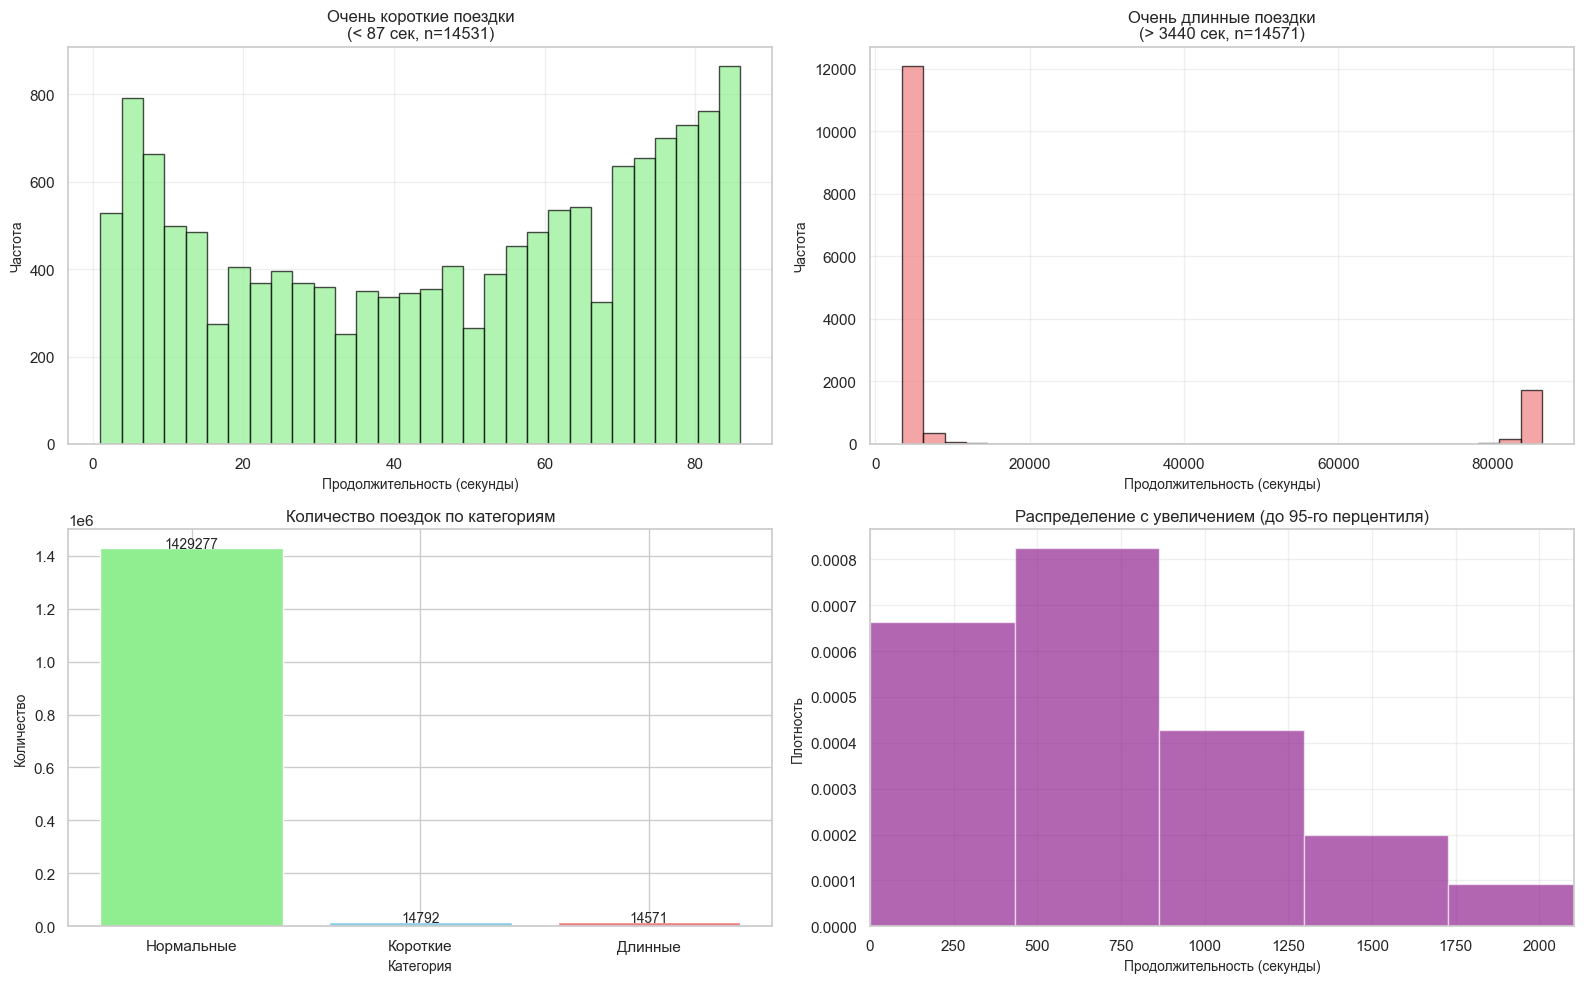

In [37]:
# Анализ редких значений - очень короткие и очень длинные поездки

# Найдем границы для "редких" значений (например, меньше 1-го перцентиля и больше 99-го)
percentiles = df['trip_duration'].quantile([0.01, 0.99]).values
rare_short = df['trip_duration'] < percentiles[0]
rare_long = df['trip_duration'] > percentiles[1]

print(f"Границы редких значений:")
print(f"1-й перцентиль (очень короткие): {percentiles[0]:.0f} сек")
print(f"99-й перцентиль (очень длинные): {percentiles[1]:.0f} сек")
print(f"Количество очень коротких поездок: {rare_short.sum()} ({rare_short.sum()/len(df)*100:.2f}%)")
print(f"Количество очень длинных поездок: {rare_long.sum()} ({rare_long.sum()/len(df)*100:.2f}%)")

# Создание графиков для редких значений
plt.figure(figsize=(16, 10))

# 1. Гистограмма для очень коротких поездок
plt.subplot(2, 2, 1)
short_durations = df[rare_short]['trip_duration'].dropna()
plt.hist(short_durations, bins=30, color='lightgreen', edgecolor='black', alpha=0.7)
plt.title(f'Очень короткие поездки\n(< {percentiles[0]:.0f} сек, n={len(short_durations)})', fontsize=12)
plt.xlabel('Продолжительность (секунды)', fontsize=10)
plt.ylabel('Частота', fontsize=10)
plt.grid(True, alpha=0.3)

# 2. Гистограмма для очень длинных поездок
plt.subplot(2, 2, 2)
long_durations = df[rare_long]['trip_duration'].dropna()
plt.hist(long_durations, bins=30, color='lightcoral', edgecolor='black', alpha=0.7)
plt.title(f'Очень длинные поездки\n(> {percentiles[1]:.0f} сек, n={len(long_durations)})', fontsize=12)
plt.xlabel('Продолжительность (секунды)', fontsize=10)
plt.ylabel('Частота', fontsize=10)
plt.grid(True, alpha=0.3)

# 3. Box plot для всех категорий
plt.subplot(2, 2, 3)
df['duration_category'] = pd.cut(df['trip_duration'], 
                                 bins=[0, percentiles[0], percentiles[1], df['trip_duration'].max()],
                                 labels=['Короткие', 'Нормальные', 'Длинные'])
category_counts = df['duration_category'].value_counts()
plt.bar(category_counts.index, category_counts.values, color=['lightgreen', 'skyblue', 'lightcoral'])
plt.title('Количество поездок по категориям', fontsize=12)
plt.xlabel('Категория', fontsize=10)
plt.ylabel('Количество', fontsize=10)
for i, v in enumerate(category_counts.values):
    plt.text(i, v + 1000, str(v), ha='center', fontsize=10)

# 4. Zoom на хвосты распределения
plt.subplot(2, 2, 4)
plt.hist(df['trip_duration'].dropna(), bins=200, color='purple', alpha=0.6, density=True)
plt.xlim(0, df['trip_duration'].quantile(0.95))  # Показываем до 95-го перцентиля
plt.title('Распределение с увеличением (до 95-го перцентиля)', fontsize=12)
plt.xlabel('Продолжительность (секунды)', fontsize=10)
plt.ylabel('Плотность', fontsize=10)
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()